<a href="https://colab.research.google.com/github/mayajdias/walmart-hurricane-project/blob/main/notebooks/team_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cleaning

## Decision Log

In [1]:
DECISIONS = []

def log(step, decision, rows_affected):
    DECISIONS.append({'step': step, 'decision': decision, 'rows': rows_affected})
    print(f'[{step}] {decision} ({rows_affected} row(s))')

## Loading Data / EDA: distribution_centers.csv

In [2]:
!git clone https://github.com/mayajdias/walmart-hurricane-project.git
import os
os.listdir('walmart-hurricane-project')

Cloning into 'walmart-hurricane-project'...
remote: Enumerating objects: 176, done.
remote: Counting objects: 100% (176/176), done.
remote: Compressing objects: 100% (155/155), done.
remote: Total 176 (delta 91), reused 30 (delta 13), pack-reused 0 (from 0)
Receiving objects: 100% (176/176), 2.51 MiB | 9.12 MiB/s, done.
Resolving deltas: 100% (91/91), done.


['.git', 'CHARTER.md', 'data', 'notebooks', 'README.md']

In [3]:
import pandas as pd, numpy as np
distribution = pd.read_csv('walmart-hurricane-project/data/distribution_centers.csv')
distribution.head()

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.0
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.5
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.0
3,DC-MIA,Miami Distribution Center,Miami,FL,350,~750,235,298.0
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,NaN


In [4]:
distribution.shape

(5, 8)

5 observations, 8 columns

In [5]:
distribution.dtypes

,0
dc_id,object
dc_name,object
city,object
state,object
avg_daily_shipments,int64
surge_capacity,object
distance_to_orlando_mi,int64
cost_per_shipment,float64


Need to change surge_capacity to int

In [6]:
distribution.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   dc_id                   5 non-null      object 
 1   dc_name                 5 non-null      object 
 2   city                    5 non-null      object 
 3   state                   5 non-null      object 
 4   avg_daily_shipments     5 non-null      int64  
 5   surge_capacity          5 non-null      object 
 6   distance_to_orlando_mi  5 non-null      int64  
 7   cost_per_shipment       4 non-null      float64
dtypes: float64(1), int64(2), object(5)
memory usage: 452.0+ bytes


In [7]:
distribution.describe()

,avg_daily_shipments,distance_to_orlando_mi,cost_per_shipment
count,5.00000,5.000000,4.000000
mean,360.00000,485.000000,410.625000
std,96.17692,377.987434,197.064023
min,250.00000,141.000000,245.000000
25%,300.00000,235.000000,284.750000
50%,350.00000,438.000000,355.250000
75%,400.00000,503.000000,481.125000
max,500.00000,1108.000000,687.000000


In [8]:
distribution.isnull().sum()

,0
dc_id,0
dc_name,0
city,0
state,0
avg_daily_shipments,0
surge_capacity,0
distance_to_orlando_mi,0
cost_per_shipment,1


1 null item in cost_per_shipment

In [9]:
distribution["state"].value_counts()

,count
state,
FL,2
GA,1
TX,1
AL,1


Cleaning Required: remove non-numerical values from surge_capacity and make integer type. Address missing value in cost_per_shipment.

## Cleaning: distribution_centers.csv

In [10]:
def clean_distributions(df):
  df = df.copy()
  if "surge_capacity" in df.columns:
    df["surge_capacity"] = df["surge_capacity"].str.extract(r"(\d+)").astype(int)
  if "cost_per_shipment" in df.columns:
        mean_cost_per_shipment = df["cost_per_shipment"].mean()
        df["cost_per_shipment"] = df["cost_per_shipment"].fillna(mean_cost_per_shipment)
  return df

In [11]:
distributions_cleaned = clean_distributions(distribution)
distributions_cleaned.head()

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.000
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.500
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.000
3,DC-MIA,Miami Distribution Center,Miami,FL,350,750,235,298.000
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,410.625


In [12]:
log("Cleaning", "converted surge_capacity to integer and addressed missing value in cost_per_shipment", "5")

[Cleaning] converted surge_capacity to integer and addressed missing value in cost_per_shipment (5 row(s))


## Loading Data / EDA: store_locations.csv

In [13]:
stores = pd.read_csv('walmart-hurricane-project/data/store_locations.csv')
stores.head()

,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL-105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL-330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL-412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central


In [14]:
stores.shape

(14, 8)

14 observations, 8 columns

In [15]:
stores.dtypes

,0
store_id,object
store_name,object
city,object
state,object
zip_code,int64
latitude,float64
longitude,float64
region,object


In [16]:
stores.duplicated().sum()

np.int64(0)

In [17]:
stores.duplicated(subset=["store_id"]).sum()

np.int64(0)

In [18]:
stores.duplicated(subset=["store_name"]).sum()

np.int64(2)

There are two duplicate store names

In [19]:
name_duplicates = stores[stores.duplicated(subset=["store_name"], keep=False)]
print(name_duplicates)

   store_id                             store_name       city    state  \
0    FL-239            Walmart Supercenter Orlando    Orlando       FL   
4    FL-287  Walmart Neighborhood Market Kissimmee  Kissimmee  Florida   
12    FL239            Walmart Supercenter Orlando    Orlando       FL   
13   FL_287  Walmart Neighborhood Market Kissimmee  Kissimmee  Florida   

    zip_code  latitude  longitude   region  
0      32801   28.5383   -81.3792  Central  
4      34741   28.2920   -81.4076  Central  
12     32801   28.5383   -81.3792  Central  
13     34741   28.2920   -81.4076  Central  


The two duplicated store names are not listed as total duplicates because store_id and state are formatted differently between them. Need to standardize format for these columns, then drop duplicate rows.

In [20]:
stores["city"].value_counts()

,count
city,
Orlando,2
Kissimmee,2
Miami,1
Tampa,1
Jacksonville,1
Daytona Beach,1
Fort Myers,1
Gainesville,1
Tallahassee,1


In [21]:
stores["state"].value_counts()

,count
state,
FL,10
Florida,3
Fla.,1


Need to standardize state name - all are in Florida, but formatted 3 ways. Should use "FL" because this is the convention in the previous data set.

In [22]:
stores["region"].value_counts()

,count
region,
Central,5
West,3
North,2
South,1
East,1
Panhandle,1
Panhandle,1


In [23]:
stores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   store_id    14 non-null     object 
 1   store_name  14 non-null     object 
 2   city        14 non-null     object 
 3   state       14 non-null     object 
 4   zip_code    14 non-null     int64  
 5   latitude    13 non-null     float64
 6   longitude   13 non-null     float64
 7   region      14 non-null     object 
dtypes: float64(2), int64(1), object(5)
memory usage: 1.0+ KB


In [24]:
stores.describe()

,zip_code,latitude,longitude
count,14.000000,13.000000,13.000000
mean,33200.428571,28.418192,-82.069631
std,893.995759,1.319349,1.676108
min,32099.000000,25.761700,-87.216900
25%,32526.000000,27.950600,-82.324800
50%,32951.000000,28.292000,-81.655700
75%,33776.000000,29.210800,-81.379200
max,34741.000000,30.421300,-80.191800


In [25]:
stores.isnull().sum()

,0
store_id,0
store_name,0
city,0
state,0
zip_code,0
latitude,1
longitude,1
region,0


In [26]:
stores[stores['latitude'].isna()]

,store_id,store_name,city,state,zip_code,latitude,longitude,region
8,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,NaN,NaN,Panhandle


In [27]:
stores[stores['longitude'].isna()]

,store_id,store_name,city,state,zip_code,latitude,longitude,region
8,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,NaN,NaN,Panhandle


The missing values for latitude and longitude are both in the same row, the Walmart Supercenter Tallahassee.

Cleaning Required: standardize store_id format by removing filler characters ("-", "_", etc.). Standardize state name by setting all to "FL". Address missing latitude and longitude for Tallahassee store. Drop duplicate rows.

## Cleaning: store_locations.csv

In [28]:
def clean_stores(df):
  df = df.copy()
  if 'store_id' in df.columns:
        df['store_id'] = df['store_id'].astype(str).str.replace(r'[^a-zA-Z0-9]', '', regex=True)
  if 'state' in df.columns:
        df['state'] = 'FL'
  if 'latitude' in df.columns:
        tallahassee_latitude = 30.4383
        df['latitude'] = df['latitude'].fillna(tallahassee_latitude)
  if 'longitude' in df.columns:
        tallahassee_longitude = -84.2807
        df['longitude'] = df['longitude'].fillna(tallahassee_longitude)
  df = df.drop_duplicates()
  return df

In [29]:
stores_cleaned = clean_stores(stores)
stores_cleaned.head()

,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.2920,-81.4076,Central


In [30]:
log("Cleaning", "standardized store_id and state, filled missing latitude and longitude", "14")

[Cleaning] standardized store_id and state, filled missing latitude and longitude (14 row(s))


In [31]:
stores_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   store_id    12 non-null     object 
 1   store_name  12 non-null     object 
 2   city        12 non-null     object 
 3   state       12 non-null     object 
 4   zip_code    12 non-null     int64  
 5   latitude    12 non-null     float64
 6   longitude   12 non-null     float64
 7   region      12 non-null     object 
dtypes: float64(2), int64(1), object(5)
memory usage: 864.0+ bytes


## Loading Data / EDA: walmart_transactions.csv

In [32]:
transactions = pd.read_csv("walmart-hurricane-project/data/walmart_transactions.csv")
transactions.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82


Need to standardize store_id

In [33]:
transactions.shape

(25562, 8)

25,562 observations, 8 columns

In [34]:
transactions.duplicated().sum()

np.int64(30)

30 duplicate rows even before cleaning

In [35]:
transactions.dtypes

,0
transaction_id,object
store_id,object
timestamp,object
sku,object
product_name,object
category,object
quantity,int64
unit_price,object


Need to make unit_price a float and timestamp a date

In [36]:
transactions["sku"].value_counts()

,count
sku,
TARP-HD,766
LED-FLASH,732
FLASH-01,728
HDTARP-01,701
CHRG-PORT,684
CANDLE-EMRG,664
CNDL-EM,652
BEER-24,643
FIRSTAID-KIT,637


Need to consolidate SKUs

### Ambiguous SKU investigation:

In [37]:
contains_STREAM = transactions[transactions['sku'].str.lower().str.contains('stream', na=False)]
contains_STREAM.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
34,TXN019961,FL-445,09-02-2024 07:05:04,STREAM-01,Roku Streaming Stick,Electronics,1,30.70
37,TXN021031,FL-501,2024-09-04T10:07:24,STREAM-01,STREAMING STICK,Electronics,1,28.65
81,TXN004193,FL-330,2024-09-18 12:03:52,STREAM-01,Streaming Device,electronics,1,30.94
162,TXN022256,FL-078,2024-09-06T20:26:50,STREAM-01,Streaming Device,Electronics,1,29.18
308,TXN009170,FL-710,2024-09-22T11:40:05,STREAM-01,STREAMING STICK,ELECTRONICS,1,28.70


SKU STREAM_01 is a Roku Streaming Stick

In [38]:
contains_TP = transactions[transactions['sku'].str.lower().str.contains('tp-12', na=False)]
contains_TP.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
45,TXN021737,FL-619,NaN,TP-12,TOILET PAPER 12PK,HOUSEHOLD,2,9.74
48,TXN013700,FL-156,09/25/2024 17:38,TP-12,Toilet Paper 12-Roll,Household,2,9.93
82,TXN020295,fl-412,2024-09-03 20:13:58,TP-12,TOILET PAPER 12PK,Household,1,9.60
103,TXN012143,FL-619,2024-09-24 17:41:44,TP-12,TP 12 Pack,Household Essentials,1,9.68
323,TXN016091,FL-105,2024-09-27 09:49:38,TP-12,Toilet Paper 12-Roll,Household Essentials,2,10.16


SKU TP-12 is toilet paper

In [39]:
contains_FAID = transactions[transactions['sku'].str.lower().str.contains('faid-01', na=False)]
contains_FAID.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
110,TXN011942,FL-078,2024-09-24 17:11:45,FAID-01,FIRST AID KIT,HEALTH,2,14.41
170,TXN005774,FL-105,09/20/2024 21:12,FAID-01,First Aid Kit,health,1,14.97
173,TXN017029,FL-330,09/28/2024 06:50,FAID-01,FIRST AID KIT,health,2,15.17
200,TXN013846,FL-501,09/25/2024 10:18,FAID-01,First Aid Kit,HEALTH,2,14.77
204,TXN022216,FL-501,2024-09-06T15:21:16,FAID-01,First-Aid Kit,Health,1,$15.05


SKU FAID-01 is a first aid kit

In [40]:
contains_PB = transactions[transactions['sku'].str.lower().str.contains('pb-16', na=False)]
contains_PB.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
26,TXN018977,FL-105,09/01/2024 06:26,PB-16,Peanut Butter 16oz,Groceries,1,3.22
102,TXN004056,FL-239,2024-09-18 08:01:34,PB-16,Peanut Butter,Groceries,1,3.23
238,TXN023524,FL-619,08-Sep-2024 16:13,PB-16,Peanut Butter,Groceries,1,$3.38
367,TXN016207,FL-412,09/27/2024 10:16,PB-16,Peanut Butter 16oz,grocery,2,3.32
395,TXN016071,FL105,2024-09-27 15:05:48,PB-16,Peanut Butter,Groceries,1,3.32


SKU PB-16 is peanut butter

In [41]:
contains_PT = transactions[transactions['sku'].str.lower().str.contains('pt-12', na=False)]
contains_PT.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
47,TXN005801,FL-330,2024-09-20 21:23:43,PT-12,Pop Tarts - Strawberry,BREAKFAST,3,3.49
138,TXN012731,FL_239,NaN,PT-12,POPTART-STRAWBERRY,BREAKFAST,4,3.56
227,TXN023448,FL-078,09/08/2024 06:10,PT-12,Strawberry Pop-Tart,Breakfast Foods,3,3.53
249,TXN018956,FL-105,2024-09-01 15:21:52,PT-12,Strawberry Pop-Tart,Breakfast Foods,4,$3.39
264,TXN019047,FL-412,01-Sep-2024 08:02,PT-12,Pop-Tarts Strawberry,BREAKFAST,3,3.57


SKU PT-12 is strawberry poptarts

In [42]:
contains_459812 = transactions[transactions['sku'].str.lower().str.contains('459812', na=False)]
contains_459812.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
27,TXN007697,FL-710,21-Sep-2024 19:46,SKU#459812,POPTART-STRAWBERRY,BREAKFAST,4,3.45
142,TXN003351,FL-330,2024-09-17 19:25:29,SKU#459812,Pop-Tarts Strawberry,Breakfast,4,3.66
180,TXN009599,FL-412,2024-09-23 15:39:21,SKU#459812,Pop-Tarts Strawberry,Breakfast,3,3.51
197,TXN012728,FL-239,2024-09-25 12:34:01,SKU#459812,pop-tarts strawberry,breakfast,1,3.58
202,TXN010186,FL-619,23-Sep-2024 17:44,SKU#459812,Strawberry Pop-Tart,breakfast,3,3.33


SKU SKU#459812 is strawberry poptarts

In [43]:
transactions.isnull().sum()

,0
transaction_id,0
store_id,0
timestamp,886
sku,0
product_name,0
category,0
quantity,0
unit_price,0


timestamp is the only column with missing values, it has 886 missing values

In [44]:
transactions["category"].value_counts()

,count
category,
EMERGENCY,1823
Emergency Supplies,1819
emergency,1789
Emergency,1764
Groceries,859
electronics,857
Electronics,845
Grocery,837
ELECTRONICS,824


Need to consolidate category names

In [45]:
transactions.describe()

,quantity
count,25562.000000
mean,1.932634
std,1.086926
min,-5.000000
25%,1.000000
50%,2.000000
75%,2.000000
max,6.000000


At least one quantity is negative (data entry error)

## Cleaning: walmart_transactions.csv

### Mapping SKUs

In [46]:
canonical_sku_groups = {
    'POPTART-STRAW': ['PT-12', 'SKU#459812', 'PT_STRAWBERRY'],
    'SOUP-CAN': ['CNSOUP-01'],
    'BG-MONO': ['GAME-MONO', 'MONOPOLY-01'],
    'BEER-24': ['LTBEER24'],
    'WTR-24': ['WTR_24PK', 'WATER24PK'],
    'CANDLE-EMRG': ['CNDL-EM'],
    'TARP-HD': ['HDTARP-01'],
    'LED-FLASH': ['FLASH-01'],
    'CHRG-PORT': ['PORTCHARGER'],
    'FIRSTAID-KIT': ['FAID-01'],
    'ROKU-STD': ['STREAM-01'],
    'PTOWEL-6': ['PAPERTOWEL6'],
    'PLAYCARD-STD': ['CARDS-01'],
    'BREAD-WH': ['WHITEBREAD'],
    'TOILETPAPER12': ['TP-12'],
    'PNUTBTR-16': ['PB-16'],
    'BABYFORMULA': ['BFORM-01'],
    'DIAPERS-3': ['DIAP-S3'],
    'BAT-AA4': ['BATT-100', 'BATT_AA_4PK'],
    'CHIPVARIETY': ['CHIPS-VP']
}

sku_mapping = {
    original: target
    for target, originals in canonical_sku_groups.items()
    for original in originals
}

### Mapping categories

In [47]:
canonical_category_groups = {
    'Emergency': ['EMERGENCY', 'Emergency Supplies', 'emergency'],
    'Grocery': ['Groceries', 'grocery', 'GROCERY'],
    'Electronics': ['electronics', 'ELECTRONICS'],
    'Entertainment': ['Games & Entertainment', 'entertainment', 'ENTERTAINMENT'],
    'Household': ['HOUSEHOLD', 'household', 'Household Essentials'],
    'Baby': ['baby', 'BABY', 'Baby Products'],
    'Breakfast': ['breakfast', 'BREAKFAST', 'Breakfast Foods'],
    'Alcohol': ['ALCOHOL', 'Alcoholic Beverages'],
    'Snacks': ['snacks', 'SNACKS'],
    'Health': ['HEALTH', 'health', 'Health & Wellness']
}

category_mapping = {
    original: target
    for target, originals in canonical_category_groups.items()
    for original in originals
}

### Applying SKU mapping

In [48]:
def consolidate_skus(df):
    df = df.copy()
    if 'sku' in df.columns:
        df['canonical_sku'] = df['sku'].map(sku_mapping).fillna(df['sku'])
    return df

transactions_skus_consolidated = consolidate_skus(transactions)
transactions_skus_consolidated.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24


In [49]:
log("Cleaning", "created canonical_sku column consolidating SKUs", "25562")

[Cleaning] created canonical_sku column consolidating SKUs (25562 row(s))


### Applying category mapping

In [50]:
def consolidate_categories(df):
    df = df.copy()
    if 'category' in df.columns:
        df['canonical_category'] = df['category'].map(category_mapping).fillna(df['category'])
    return df

transactions_fully_consolidated = consolidate_categories(transactions_skus_consolidated)
transactions_fully_consolidated.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku,canonical_category
0,TXN012636,FL-710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16,Grocery
1,TXN000759,fl-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN,Grocery
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12,Household
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD,Electronics
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24,Alcohol


In [51]:
log("Cleaning", "created canonical_category column consolidating categories", "25562")

[Cleaning] created canonical_category column consolidating categories (25562 row(s))


### Cleaning unit_price and store_id columns

In [52]:
def clean_transactions(df):
  df = df.copy()
  if 'store_id' in df.columns:
        df['store_id'] = (df['store_id'].astype(str).str.upper().str.replace(r'[^A-Z0-9]', '', regex=True))
  if 'unit_price' in df.columns:
        df['unit_price'] = (df['unit_price'].astype(str).str.replace(r'[^\d.]', '', regex=True).astype(float))
  df = df.drop_duplicates().reset_index(drop=True)
  return df

In [53]:
print("Length before:", len(transactions_fully_consolidated))
transactions_cleaned_price_id = clean_transactions(transactions_fully_consolidated)
print("Length after:", len(transactions_cleaned_price_id))
print("Rows removed:", len(transactions_fully_consolidated) - len(transactions_cleaned_price_id))
transactions_cleaned_price_id.head()

Length before: 25562
Length after: 25532
Rows removed: 30


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku,canonical_category
0,TXN012636,FL710,2024-09-24T09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16,Grocery
1,TXN000759,FL412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN,Grocery
2,TXN003338,FL105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12,Household
3,TXN025020,FL330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD,Electronics
4,TXN015797,FL302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24,Alcohol


In [54]:
log("Cleaning", "cleaned and standardized store_id and unit_price", "25562")

[Cleaning] cleaned and standardized store_id and unit_price (25562 row(s))


In [55]:
log("Cleaning", "dropped duplicate rows", "30")

[Cleaning] dropped duplicate rows (30 row(s))


### Cleaning timestamp column

In [56]:
def clean_timestamp(df):
    df = df.copy()
    if 'timestamp' in df.columns:
        df['timestamp'] = pd.to_datetime(df['timestamp'], format='mixed', errors='coerce')
        df = df.dropna(subset=['timestamp'])
    return df

In [57]:
print("Length before:", len(transactions_cleaned_price_id))
transactions_timestamps_cleaned = clean_timestamp(transactions_cleaned_price_id)
print("Length after:", len(transactions_timestamps_cleaned))
print("Rows removed:", len(transactions_cleaned_price_id) - len(transactions_timestamps_cleaned))
transactions_timestamps_cleaned.head()

Length before: 25532
Length after: 24648
Rows removed: 884


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku,canonical_category
0,TXN012636,FL710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16,Grocery
1,TXN000759,FL412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN,Grocery
2,TXN003338,FL105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12,Household
3,TXN025020,FL330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD,Electronics
4,TXN015797,FL302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24,Alcohol


In [58]:
log("Cleaning", "converted timestamp column to consistent datetime format", "25532")

[Cleaning] converted timestamp column to consistent datetime format (25532 row(s))


In [59]:
log("Cleaning", "removed rows with missing timestamp", "884")

[Cleaning] removed rows with missing timestamp (884 row(s))


### Fixing negative values

In [60]:
transactions_timestamps_cleaned.describe()

,timestamp,quantity,unit_price
count,24648,24648.000000,24648.000000
mean,2024-09-18 08:38:46.325137920,1.933625,12.559016
min,2024-09-01 06:01:15,-5.000000,1.890000
25%,2024-09-11 16:56:12.750000128,1.000000,4.930000
50%,2024-09-20 16:25:52,2.000000,9.240000
75%,2024-09-24 21:30:09.249999872,2.000000,19.790000
max,2024-09-30 22:57:47,6.000000,31.490000
std,NaN,1.087472,9.022267


In [61]:
def positive_quantities(df):
  df = df.copy()
  if 'quantity' in df.columns:
    df['quantity'] = pd.to_numeric(df['quantity'], errors="coerce").abs()
  return df

In [62]:
transactions_positive_quantities = positive_quantities(transactions_timestamps_cleaned)
transactions_positive_quantities.describe()

,timestamp,quantity,unit_price
count,24648,24648.000000,24648.000000
mean,2024-09-18 08:38:46.325137920,1.952856,12.559016
min,2024-09-01 06:01:15,1.000000,1.890000
25%,2024-09-11 16:56:12.750000128,1.000000,4.930000
50%,2024-09-20 16:25:52,2.000000,9.240000
75%,2024-09-24 21:30:09.249999872,2.000000,19.790000
max,2024-09-30 22:57:47,6.000000,31.490000
std,NaN,1.052545,9.022267


### Checking for whitespace

In [63]:
transactions_positive_quantities['sku'].dropna().astype(str).str.startswith(' ').sum()

np.int64(0)

In [64]:
transactions_positive_quantities['sku'].dropna().astype(str).str.endswith(' ').sum()

np.int64(0)

No whitespace in sku column

In [65]:
transactions_positive_quantities['category'].dropna().astype(str).str.startswith(' ').sum()

np.int64(0)

In [66]:
transactions_positive_quantities['category'].dropna().astype(str).str.endswith(' ').sum()

np.int64(0)

No whitespace in category column

In [67]:
transactions_positive_quantities['store_id'].dropna().astype(str).str.startswith(' ').sum()

np.int64(0)

In [68]:
transactions_positive_quantities['store_id'].dropna().astype(str).str.endswith(' ').sum()

np.int64(0)

No whitespace in store_id column

In [69]:
transactions_positive_quantities['product_name'].dropna().astype(str).str.startswith(' ').sum()

np.int64(333)

In [70]:
transactions_positive_quantities['product_name'].dropna().astype(str).str.endswith(' ').sum()

np.int64(333)

Whitespace in product_name column

### Cleaning product_name column

In [71]:
contains_pop = transactions[transactions['product_name'].str.lower().str.contains('pop', na=False)]
contains_pop['product_name'].value_counts()

,count
product_name,
POPTART-STRAWBERRY,386
Pop Tarts - Strawberry,358
Pop-Tarts Strawberry,341
Pop-Tarts Strawberry,331
pop-tarts strawberry,328
Strawberry Pop-Tart,319


In [72]:
contains_water = transactions[transactions['product_name'].str.lower().str.contains('water', na=False)]
contains_water['product_name'].value_counts()

,count
product_name,
Bottled Water 24-Pack,509
BOTTLED WATER 24PK,501
Water - 24 Pack,480


In [73]:
contains_beer = transactions[transactions['product_name'].str.lower().str.contains('beer', na=False)]
contains_beer['product_name'].value_counts()

,count
product_name,
Light Beer 24pk,455
BEER LIGHT 24PK,412
Light Beer (24-pack),402


In [74]:
contains_soup = transactions[transactions['product_name'].str.lower().str.contains('soup', na=False)]
contains_soup['product_name'].value_counts()

,count
product_name,
Soup - Canned,363
Canned Soup,350
CANNED SOUP,339


In [75]:
contains_mono = transactions[transactions['product_name'].str.lower().str.contains('mono', na=False)]
contains_mono['product_name'].value_counts()

,count
product_name,
Board Game - Monopoly,459
Monopoly Board Game,450
MONOPOLY,433


In [76]:
contains_candle = transactions[transactions['product_name'].str.lower().str.contains('candle', na=False)]
contains_candle['product_name'].value_counts()

,count
product_name,
CANDLES - EMERGENCY,456
Emergency Candles,450
Candles (Emergency),410


In [77]:
contains_tarp = transactions[transactions['product_name'].str.lower().str.contains('tarp', na=False)]
contains_tarp['product_name'].value_counts()

,count
product_name,
Heavy Duty Tarp,510
TARP - HEAVY DUTY,492
HD Tarp,465


In [78]:
contains_flash = transactions[transactions['product_name'].str.lower().str.contains('flash', na=False)]
contains_flash['product_name'].value_counts()

,count
product_name,
LED Flashlight,518
FLASHLIGHT LED,477
Flashlight - LED,465


In [79]:
contains_charg = transactions[transactions['product_name'].str.lower().str.contains('charg', na=False)]
contains_charg['product_name'].value_counts()

,count
product_name,
Phone Charger - Portable,465
Portable Phone Charger,443
PORTABLE CHARGER,408


In [80]:
contains_aid = transactions[transactions['product_name'].str.lower().str.contains('aid', na=False)]
contains_aid['product_name'].value_counts()

,count
product_name,
First-Aid Kit,427
FIRST AID KIT,407
First Aid Kit,397


In [81]:
contains_stream = transactions[transactions['product_name'].str.lower().str.contains('stream', na=False)]
contains_stream['product_name'].value_counts()

,count
product_name,
Streaming Device,454
STREAMING STICK,392
Roku Streaming Stick,364


In [82]:
contains_towel = transactions[transactions['product_name'].str.lower().str.contains('towel', na=False)]
contains_towel['product_name'].value_counts()

,count
product_name,
Paper Towels 6-Roll,406
PAPER TOWELS 6PK,405
Paper Towels,360


In [83]:
contains_card = transactions[transactions['product_name'].str.lower().str.contains('card', na=False)]
contains_card['product_name'].value_counts()

,count
product_name,
Playing Cards,404
Standard Playing Cards,403
PLAYING CARDS,392


In [84]:
contains_bread = transactions[transactions['product_name'].str.lower().str.contains('bread', na=False)]
contains_bread['product_name'].value_counts()

,count
product_name,
White Bread,410
WHITE BREAD,381
Bread - White,374


In [85]:
contains_toilet = transactions[transactions['product_name'].str.lower().str.contains('toilet', na=False)]
contains_toilet['product_name'].value_counts()

,count
product_name,
TOILET PAPER 12PK,406
Toilet Paper 12-Roll,396


In [86]:
contains_nut = transactions[transactions['product_name'].str.lower().str.contains('nut', na=False)]
contains_nut['product_name'].value_counts()

,count
product_name,
Peanut Butter 16oz,400
PEANUT BUTTER,357
Peanut Butter,341


In [87]:
contains_formula = transactions[transactions['product_name'].str.lower().str.contains('formula', na=False)]
contains_formula['product_name'].value_counts()

,count
product_name,
BABY FORMULA,361
Infant Formula,355
Baby Formula,339


In [88]:
contains_diaper = transactions[transactions['product_name'].str.lower().str.contains('diaper', na=False)]
contains_diaper['product_name'].value_counts()

,count
product_name,
Diapers Size 3,360
DIAPERS SZ 3,339
Baby Diapers - Size 3,336


In [89]:
contains_bat = transactions[transactions['product_name'].str.lower().str.contains('bat', na=False)]
contains_bat['product_name'].value_counts()

,count
product_name,
AA Batteries 4-Pack,516
BATTERIES AA 4PK,475
AA Batteries (4-pack),471


In [90]:
contains_chip = transactions[transactions['product_name'].str.lower().str.contains('chip', na=False)]
contains_chip['product_name'].value_counts()

,count
product_name,
Variety Pack - Chips,350
CHIPS VARIETY PACK,317
Chips Variety Pack,314


In [91]:
canonical_product_names = {
    'Strawberry Pop-Tart': ['POPTART-STRAWBERRY', 'Pop Tarts - Strawberry', 'Pop-Tarts Strawberry', 'pop-tarts strawberry'],
    'Bottled Water (24 pack)': ['Bottled Water 24-Pack', 'BOTTLED WATER 24PK', 'Water - 24 Pack'],
    'Light Beer (24 pack)': ['Light Beer 24pk', 'BEER LIGHT 24PK', 'Light Beer (24-pack)'],
    'Canned Soup': ['Soup - Canned', 'CANNED SOUP'],
    'Monopoly Board Game': ['Board Game - Monopoly', 'MONOPOLY'],
    'Emergency Candles': ['CANDLES - EMERGENCY', 'Candles (Emergency)'],
    'Heavy Duty Tarp': ['TARP - HEAVY DUTY', 'HD Tarp'],
    'LED Flashlight': ['FLASHLIGHT LED', 'Flashlight - LED'],
    'Portable Phone Charger': ['Phone Charger - Portable', 'PORTABLE CHARGER'],
    'First Aid Kit': ['FIRST AID KIT', 'First-Aid Kit'],
    'Streaming Stick': ['Streaming Device', 'STREAMING STICK', 'Roku Streaming Stick'],
    'Paper Towels': ['Paper Towels 6-Roll', 'PAPER TOWELS 6PK'],
    'Playing Cards': ['Standard Playing Cards', 'PLAYING CARDS'],
    'White Bread': ['WHITE BREAD', 'Bread - White'],
    'Toilet Paper (12 pack)': ['TOILET PAPER 12PK', 'Toilet Paper 12-Roll'],
    'Peanut Butter': ['Peanut Butter 16oz', 'PEANUT BUTTER'],
    'Baby Formula': ['BABY FORMULA', 'Infant Formula'],
    'Diapers (Size 3)': ['Diapers Size 3', 'DIAPERS SZ 3', 'Baby Diapers - Size 3'],
    'AA Batteries (4 pack)': ['AA Batteries 4-Pack', 'BATTERIES AA 4PK', 'AA Batteries (4-pack)'],
    'Chips (Variety Pack)': ['Variety Pack - Chips', 'CHIPS VARIETY PACK', 'Chips Variety Pack']
}

product_name_mapping = {
    original: target
    for target, originals in canonical_product_names.items()
    for original in originals
}

In [92]:
def consolidate_product_names(df):
    df = df.copy()
    if 'product_name' in df.columns:
        clean_name = df['product_name'].astype(str).str.strip()
        df['canonical_product_name'] = clean_name.map(product_name_mapping).fillna(clean_name)
    return df

transactions_product_names_consolidated = consolidate_product_names(transactions_positive_quantities)
transactions_product_names_consolidated.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku,canonical_category,canonical_product_name
0,TXN012636,FL710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16,Grocery,Peanut Butter
1,TXN000759,FL412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN,Grocery,Canned Soup
2,TXN003338,FL105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12,Household,Toilet Paper (12 pack)
3,TXN025020,FL330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD,Electronics,Streaming Stick
4,TXN015797,FL302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24,Alcohol,Light Beer (24 pack)


In [93]:
log("Cleaning", "consolidated product_name to one name per product type", "24648")

[Cleaning] consolidated product_name to one name per product type (24648 row(s))


In [94]:
walmart_transactions_cleaned = transactions_product_names_consolidated.copy()
walmart_transactions_cleaned.to_csv('walmart_transactions_cleaned.csv', index = False)
walmart_transactions_cleaned.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku,canonical_category,canonical_product_name
0,TXN012636,FL710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16,Grocery,Peanut Butter
1,TXN000759,FL412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN,Grocery,Canned Soup
2,TXN003338,FL105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12,Household,Toilet Paper (12 pack)
3,TXN025020,FL330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD,Electronics,Streaming Stick
4,TXN015797,FL302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24,Alcohol,Light Beer (24 pack)


## Loading Data / EDA: product_catalog.csv

In [95]:
catalog = pd.read_csv("walmart-hurricane-project/data/product_catalog (1).csv")
catalog.head()

,sku,product_name,category,subcategory,unit_cost,supplier,package_size
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack


Need to use previous mappings to consolidate sku, product_name, category

Need to standardize package_size

Need to address misaligned suppliers

In [96]:
catalog.shape

(45, 7)

In [97]:
catalog.dtypes

,0
sku,object
product_name,object
category,object
subcategory,object
unit_cost,float64
supplier,object
package_size,object


In [98]:
catalog.isna().sum()

,0
sku,0
product_name,0
category,0
subcategory,13
unit_cost,5
supplier,0
package_size,0


Missing values in subcategory and unit_cost

In [99]:
catalog[catalog['unit_cost'].isna()]

,sku,product_name,category,subcategory,unit_cost,supplier,package_size
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack
7,BATT-100,BATTERIES AA 4PK,Emergency Supplies,AA,NaN,3M Company,6 pack
10,FLASH-01,FLASHLIGHT LED,Emergency,Flashlight,NaN,Frito-Lay,6-pack
16,GAME-MONO,Board Game - Monopoly,ENTERTAINMENT,NaN,NaN,Campbell's,1pk
44,HDTARP-01,TARP - HEAVY DUTY,emergency,Tarp,NaN,J.M. Smucker,24pk


## Cleaning: product_catalog.csv

In [100]:
def strip_whitespace(df):
  df = df.copy()
  text_cols = df.select_dtypes(include=["object", "string"]).columns
  for col in text_cols:
        df[col] = df[col].apply(lambda x: x.strip() if isinstance(x, str) else x)
  return df

catalog_stripped = strip_whitespace(catalog)

In [101]:
catalog_consolidated_skus = consolidate_skus(catalog_stripped)
catalog_consolidated_categories = consolidate_categories(catalog_consolidated_skus)
catalog_consolidated_products = consolidate_product_names(catalog_consolidated_categories)
catalog_consolidated_products.head()

,sku,product_name,category,subcategory,unit_cost,supplier,package_size,canonical_sku,canonical_category,canonical_product_name
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4-pack,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4pk,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6 pack,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4 pack,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1 pack,WTR-24,Emergency,Bottled Water (24 pack)


In [102]:
log("Cleaning", "consolidated SKUs, categories, and product names", "45")

[Cleaning] consolidated SKUs, categories, and product names (45 row(s))


In [103]:
catalog_consolidated_products['canonical_sku'].value_counts()

,count
canonical_sku,
POPTART-STRAW,4
WTR-24,3
BAT-AA4,3
BG-MONO,3
LED-FLASH,2
BEER-24,2
PLAYCARD-STD,2
ROKU-STD,2
SOUP-CAN,2


In [104]:
catalog_consolidated_products['canonical_category'].value_counts()

,count
canonical_category,
Emergency,12
Grocery,6
Entertainment,5
Breakfast,4
Electronics,4
Baby,4
Household,4
Alcohol,2
Snacks,2


In [105]:
catalog_consolidated_products['canonical_product_name'].value_counts()

,count
canonical_product_name,
Strawberry Pop-Tart,4
Bottled Water (24 pack),3
AA Batteries (4 pack),3
Monopoly Board Game,3
LED Flashlight,2
Light Beer (24 pack),2
Playing Cards,2
Streaming Stick,2
Canned Soup,2


In [106]:
catalog_consolidated_products['package_size'].value_counts()

,count
package_size,
single,6
1 pack,4
6 pack,4
24-pack,4
12 pack,4
4 pack,4
4pk,3
4-pack,3
24 pack,3


In [107]:
def clean_package_size(df):
    df = df.copy()
    if 'package_size' in df.columns:
        s = df['package_size'].astype(str).str.strip().str.lower()
        numeric_count = s.str.extract(r"(\d+)", expand=False)
        numeric_count = numeric_count.where(~s.isin(["single", "bundle"]), "1")
        df["package_size"] = pd.to_numeric(numeric_count, errors="coerce").astype("Int64")
    return df

In [108]:
catalog_package_clean = clean_package_size(catalog_consolidated_products)
catalog_package_clean.head()

,sku,product_name,category,subcategory,unit_cost,supplier,package_size,canonical_sku,canonical_category,canonical_product_name
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,NaN,Campbell's,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1,WTR-24,Emergency,Bottled Water (24 pack)


In [109]:
log("Cleaning", "standardized package_size and made integer", "45")

[Cleaning] standardized package_size and made integer (45 row(s))


In [110]:
def clean_unit_cost(df):
    df = df.copy()
    if "unit_cost" in df.columns:
        df["unit_cost"] = df["unit_cost"].fillna(df.groupby("canonical_sku")["unit_cost"].transform("mean"))
        df["unit_cost"] = df["unit_cost"].round(2)
    return df

catalog_cleaned_cost = clean_unit_cost(catalog_package_clean)
catalog_cleaned_cost.head()

,sku,product_name,category,subcategory,unit_cost,supplier,package_size,canonical_sku,canonical_category,canonical_product_name
0,PT-12,pop-tarts strawberry,Breakfast Foods,NaN,1.93,Johnson & Johnson,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
1,SKU#459812,Strawberry Pop-Tart,Breakfast,Pop-Tarts,2.26,Roku Inc,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
2,POPTART-STRAW,Pop-Tarts Strawberry,Breakfast,NaN,2.11,Sara Lee,6,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
3,PT_STRAWBERRY,pop-tarts strawberry,breakfast,Pop-Tarts,2.10,Campbell's,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
4,WTR-24,BOTTLED WATER 24PK,Emergency Supplies,Bottled,2.64,Sara Lee,1,WTR-24,Emergency,Bottled Water (24 pack)


In [111]:
catalog_clean = catalog_cleaned_cost.drop(columns=["sku", "product_name", "category", "subcategory", "supplier"]).copy()
catalog_clean.head()

,unit_cost,package_size,canonical_sku,canonical_category,canonical_product_name
0,1.93,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
1,2.26,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
2,2.11,6,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
3,2.10,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
4,2.64,1,WTR-24,Emergency,Bottled Water (24 pack)


In [112]:
log("Cleaning", "imputed missing unit costs by imputing mean cost for identical products", "45")
log("Cleaning", "removed supplier column because it is completely disordered and not necessary for further analysis", "45")
log("Cleaning", "removed subcategory column as it currently has no useful information and is not necessary for future analysis", "45")

[Cleaning] imputed missing unit costs by imputing mean cost for identical products (45 row(s))
[Cleaning] removed supplier column because it is completely disordered and not necessary for further analysis (45 row(s))
[Cleaning] removed subcategory column as it currently has no useful information and is not necessary for future analysis (45 row(s))


## Loading Data: inventory_and_sales.db

In [113]:
import sqlite3
conn = sqlite3.connect('walmart-hurricane-project/data/inventory_and_sales.db')
daily_sales = pd.read_sql_query("SELECT * FROM daily_sales_summary", conn)
inventory = pd.read_sql_query("SELECT * FROM inventory_levels", conn)

## EDA: daily_sales

In [114]:
daily_sales.head()

,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL-239,Emergency,90.0,1582.55
1,2024-09-12,FL-239,Breakfast,57.0,356.99
2,2024-09-12,FL-239,Alcohol,41.0,246.65
3,2024-09-12,FL-239,Entertainment,53.0,916.56
4,2024-09-12,FL-239,Grocery,69.0,339.30


Need to standardize store_id and date to match other datasets

In [115]:
daily_sales.shape

(3600, 5)

In [116]:
daily_sales.isnull().sum()

,0
date,0
store_id,0
category,0
total_units,0
total_revenue,0


In [117]:
daily_sales.describe()

,total_units,total_revenue
count,3600.000000,3600.000000
mean,65.871944,745.519383
std,43.103477,650.996412
min,14.000000,-3250.540000
25%,39.000000,340.150000
50%,56.000000,601.570000
75%,79.000000,970.390000
max,434.000000,7563.100000


At least 1 negative value in total_revenue

In [118]:
daily_sales["category"].value_counts()

,count
category,
Emergency,360
Breakfast,360
Alcohol,360
Entertainment,360
Grocery,360
Electronics,360
Snacks,360
Household,360
Health,360


category column is already correctly formatted

In [119]:
daily_sales.dtypes

,0
date,object
store_id,object
category,object
total_units,float64
total_revenue,float64


Steps: drop whitespace. Drop duplicates. Fix negative revenue. Drop dash from store_id. Convert date to timestamp.

## Cleaning: daily_sales

In [120]:
sales_no_ws = strip_whitespace(daily_sales)
sales_no_dup = sales_no_ws.drop_duplicates().reset_index(drop=True)

def positive_revenue(df):
  df = df.copy()
  if 'total_revenue' in df.columns:
    df['total_revenue'] = pd.to_numeric(df['total_revenue'], errors="coerce").abs()
  return df

sales_positive_revenue = positive_revenue(sales_no_dup)

def clean_store_id(df):
    df = df.copy()
    if 'store_id' in df.columns:
        df['store_id'] = (df['store_id'].astype(str).str.upper().str.replace(r'[^A-Z0-9]', '', regex=True))
    return df

sales_cleaned_store_id = clean_store_id(sales_positive_revenue)

def clean_timestamp(df):
    df = df.copy()
    if 'date' in df.columns:
        df['date'] = pd.to_datetime(df['date'], format='mixed', errors='coerce')
        df = df.dropna(subset=['date'])
    return df

daily_sales_clean = clean_timestamp(sales_cleaned_store_id)
daily_sales_clean.head()

,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL239,Emergency,90.0,1582.55
1,2024-09-12,FL239,Breakfast,57.0,356.99
2,2024-09-12,FL239,Alcohol,41.0,246.65
3,2024-09-12,FL239,Entertainment,53.0,916.56
4,2024-09-12,FL239,Grocery,69.0,339.30


In [121]:
log("Cleaning", "converted negative revenue to positive, cleaned store_id, converted date to standardized timestamp", "3600")

[Cleaning] converted negative revenue to positive, cleaned store_id, converted date to standardized timestamp (3600 row(s))


## EDA: inventory

In [122]:
inventory.head()

,date,store_id,sku,units_on_hand,units_on_order,reorder_point
0,2024-09-12,FL-239,CHIPS-VP,112,5.0,31
1,2024-09-12,FL-239,PAPERTOWEL6,106,46.0,36
2,2024-09-12,FL-239,PT-12,62,36.0,30
3,2024-09-12,FL-239,PORTCHARGER,185,62.0,40
4,2024-09-12,FL-239,BFORM-01,88,1.0,35


Need to apply sku mapping

Need to standardize store_id format to match other datasets

In [123]:
inventory.shape

(4320, 6)

In [124]:
inventory.describe()

,units_on_hand,units_on_order,reorder_point
count,4320.000000,3694.000000,4320.000000
mean,77.276389,49.783703,34.932407
std,47.828725,29.198093,8.931271
min,5.000000,0.000000,20.000000
25%,39.000000,25.000000,27.000000
50%,69.000000,50.000000,35.000000
75%,106.000000,75.000000,43.000000
max,200.000000,100.000000,50.000000


In [125]:
inventory.dtypes

,0
date,object
store_id,object
sku,object
units_on_hand,int64
units_on_order,float64
reorder_point,int64


Need to convert date to timestamp

In [126]:
inventory.isna().sum()

,0
date,0
store_id,0
sku,0
units_on_hand,0
units_on_order,626
reorder_point,0


Missing values in units_on_order - need to convert to 0

Steps: drop duplicates. Remove whitespace. Address missing units_on_order. Clean store_id. Consolidate SKUs. Convert date to timestamp.

## Cleaning: inventory

In [127]:
inventory_no_ws = strip_whitespace(inventory)
inventory_no_dup = inventory_no_ws.drop_duplicates().reset_index(drop=True)

def clean_inventory_units(df):
    df = df.copy()
    if "units_on_order" in df.columns:
        df["units_on_order"] = df["units_on_order"].fillna(0).astype(int)
    return df

inventory_no_na = clean_inventory_units(inventory_no_dup)
inventory_cleaned_store_id = clean_store_id(inventory_no_na)
inventory_consolidated_skus = consolidate_skus(inventory_cleaned_store_id)
inventory_clean_time = clean_timestamp(inventory_consolidated_skus)
inventory_clean = inventory_clean_time.drop(columns=["sku"]).copy()
inventory_clean.head()

,date,store_id,units_on_hand,units_on_order,reorder_point,canonical_sku
0,2024-09-12,FL239,112,5,31,CHIPVARIETY
1,2024-09-12,FL239,106,46,36,PTOWEL-6
2,2024-09-12,FL239,62,36,30,POPTART-STRAW
3,2024-09-12,FL239,185,62,40,CHRG-PORT
4,2024-09-12,FL239,88,1,35,BABYFORMULA


In [128]:
log("Cleaning", "dropped duplicates, removed whitespace, standardized store_id", "4320")

[Cleaning] dropped duplicates, removed whitespace, standardized store_id (4320 row(s))


In [129]:
log("Cleaning", "viewed missing values in units_on_reorder as meaning no units, filled with 0", "626")

[Cleaning] viewed missing values in units_on_reorder as meaning no units, filled with 0 (626 row(s))


In [130]:
log("Cleaning", "consolidated SKUs to match other data", "4320")

[Cleaning] consolidated SKUs to match other data (4320 row(s))


In [131]:
log("Cleaning", "converted date to datatime format", "4320")

[Cleaning] converted date to datatime format (4320 row(s))


# Cleaning Summary

### Final Datasets:

distributions_cleaned, stores_cleaned, walmart_transactions_cleaned, catalog_clean, daily_sales_clean, inventory_clean

Distribution Centers:

In [132]:
distributions_cleaned.head()

,dc_id,dc_name,city,state,avg_daily_shipments,surge_capacity,distance_to_orlando_mi,cost_per_shipment
0,DC-JAX,Jacksonville Distribution Center,Jacksonville,FL,500,1000,141,245.000
1,DC-ATL,Atlanta Distribution Center,Atlanta,GA,400,700,438,412.500
2,DC-DAL,Dallas Distribution Center,Dallas,TX,300,600,1108,687.000
3,DC-MIA,Miami Distribution Center,Miami,FL,350,750,235,298.000
4,DC-BHM,Birmingham Distribution Center,Birmingham,AL,250,500,503,410.625


Store Locations:

In [133]:
stores_cleaned.head()

,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
1,FL105,Walmart Supercenter Tampa,Tampa,FL,33602,27.9506,-82.4572,West
2,FL330,Walmart Supercenter Miami,Miami,FL,33101,25.7617,-80.1918,South
3,FL412,Walmart Supercenter Jacksonville,Jacksonville,FL,32099,30.3322,-81.6557,North
4,FL287,Walmart Neighborhood Market Kissimmee,Kissimmee,FL,34741,28.2920,-81.4076,Central


Walmart Transactions:

In [134]:
walmart_transactions_cleaned.head()

,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku,canonical_category,canonical_product_name
0,TXN012636,FL710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16,Grocery,Peanut Butter
1,TXN000759,FL412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN,Grocery,Canned Soup
2,TXN003338,FL105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12,Household,Toilet Paper (12 pack)
3,TXN025020,FL330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD,Electronics,Streaming Stick
4,TXN015797,FL302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24,Alcohol,Light Beer (24 pack)


Product Catalog:

In [135]:
catalog_clean.head()

,unit_cost,package_size,canonical_sku,canonical_category,canonical_product_name
0,1.93,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
1,2.26,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
2,2.11,6,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
3,2.10,4,POPTART-STRAW,Breakfast,Strawberry Pop-Tart
4,2.64,1,WTR-24,Emergency,Bottled Water (24 pack)


Daily Sales:

In [136]:
daily_sales_clean.head()

,date,store_id,category,total_units,total_revenue
0,2024-09-12,FL239,Emergency,90.0,1582.55
1,2024-09-12,FL239,Breakfast,57.0,356.99
2,2024-09-12,FL239,Alcohol,41.0,246.65
3,2024-09-12,FL239,Entertainment,53.0,916.56
4,2024-09-12,FL239,Grocery,69.0,339.30


Inventory:

In [137]:
inventory_clean.head()

,date,store_id,units_on_hand,units_on_order,reorder_point,canonical_sku
0,2024-09-12,FL239,112,5,31,CHIPVARIETY
1,2024-09-12,FL239,106,46,36,PTOWEL-6
2,2024-09-12,FL239,62,36,30,POPTART-STRAW
3,2024-09-12,FL239,185,62,40,CHRG-PORT
4,2024-09-12,FL239,88,1,35,BABYFORMULA


# Weather API and Join

### Necessary Imports

In [138]:
import pandas as pd
import requests
import time

### Weather API Function

In [139]:
BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}

def weather_retrieval(start, end, lat=28.54, lon=-81.38, tries=3):
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': 'precipitation_sum,windspeed_10m_max,pressure_msl_mean',
        'timezone': 'America/New_York',
    }

    for attempt in range(1, tries + 1):
        try:
            r = requests.get(BASE, params=params, timeout=10)
        except (requests.Timeout, requests.ConnectionError):
            if attempt == tries:
                raise
            time.sleep(2 ** attempt)
            continue
        if r.status_code in RETRY_STATUSES:
            if attempt == tries:
                r.raise_for_status()
            time.sleep(2 ** attempt)
            continue
        r.raise_for_status()
        frame = pd.DataFrame(r.json()['daily'])
        frame = frame.rename(columns={'time': 'date'})
        frame['date'] = pd.to_datetime(frame['date'])
        frame['source'] = 'open-meteo'
        return frame

All weather is pulled from Orlando.  
Weather API Source: Open-Meteo   
Base URL: https://archive-api.open-meteo.com/v1/archive

#### Fallback Data If API Fails

In [140]:
FALLBACK = pd.DataFrame({
    'date': pd.date_range('2024-09-01', periods=30),
    'precipitation_sum': [3.0, 12.4, 24.9, 22.1, 23.1, 9.3, 6.8, 94.7, 28.0, 14.4,
                          12.0, 0.7, 0.6, 21.1, 1.2, 7.9, 2.3, 13.3, 1.4, 0.7,
                          0.4, 2.2, 1.3, 0.3, 6.4, 15.2, 2.5, 18.0, 4.6, 3.3],
    'windspeed_10m_max': [18.8, 13.5, 22.8, 15.5, 15.2, 9.0, 14.2, 12.6, 11.5, 14.3,
                          15.8, 12.1, 10.4, 17.4, 9.0, 13.3, 12.4, 9.3, 12.9, 15.3,
                          19.9, 17.9, 16.6, 17.7, 27.2, 48.8, 45.1, 19.8, 11.7, 8.6],
    'pressure_msl_mean': [1014.1, 1014.1, 1015.7, 1017.8, 1017.3, 1014.3, 1011.9, 1013.8,
                          1015.7, 1014.3, 1012.3, 1011.8, 1012.7, 1012.2, 1011.8, 1012.9, 1013.7,
                          1012.9, 1011.2, 1010.6, 1012.5, 1012.7, 1013.2, 1013.5, 1011.7, 1004.1, 1006.7, 1012.3, 1013.1, 1013.8],
    'source': 'fallback sample',
})

### Weather/Sales Join Function

In [141]:
def weather_sales_join(sales_data, weather_data):
    sales_data = sales_data.copy()
    sales_data['date'] = sales_data['timestamp'].dt.normalize()

    merged = sales_data.merge(weather_data, on='date', how='left', indicator=True, validate='many_to_one')
    unmatched = merged.loc[merged['_merge'] == 'left_only', 'date'].drop_duplicates()

    print(merged['_merge'].value_counts())
    print('Number of sales days with no weather:', len(unmatched))
    if(len(unmatched) > 0):
        print('Sales days with no weather:', unmatched.dt.date.tolist())
    print('Rows kept by the left join:', len(merged), 'of', len(sales_data))

    assert len(merged) == len(sales_data), 'The join changed the row count.'
    assert merged['quantity'].sum() == sales_data['quantity'].sum(), 'The quantity total changed.'
    assert len(unmatched) == 0, 'There are sales days with no weather.'
    print('All checks passed.')

    return merged

Weather and sales data both use the America/New York timezone. The date column uses dt.normalize() to set all timestamps' time to 00:00:00 so that only date is considered.

### Weather API and Join Results

In [142]:
try:
    weather = weather_retrieval('2024-09-01', '2024-09-30')
    print('Weather retrieval succeeded.')
except requests.RequestException as err:
    print('API call failed:', err)
    weather = FALLBACK
print('Weather source used:', weather['source'].iloc[0])
weather_sales_table = weather_sales_join(walmart_transactions_cleaned, weather)
weather_sales_table.head()

Weather retrieval succeeded.
Weather source used: open-meteo
_merge
both          24648
left_only         0
right_only        0
Name: count, dtype: int64
Number of sales days with no weather: 0
Rows kept by the left join: 24648 of 24648
All checks passed.


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,canonical_sku,canonical_category,canonical_product_name,date,precipitation_sum,windspeed_10m_max,pressure_msl_mean,source,_merge
0,TXN012636,FL710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PNUTBTR-16,Grocery,Peanut Butter,2024-09-24,0.3,17.7,1013.5,open-meteo,both
1,TXN000759,FL412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,GROCERY,1,2.02,SOUP-CAN,Grocery,Canned Soup,2024-09-13,0.6,10.4,1012.7,open-meteo,both
2,TXN003338,FL105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household Essentials,2,10.47,TOILETPAPER12,Household,Toilet Paper (12 pack),2024-09-17,2.3,12.4,1013.7,open-meteo,both
3,TXN025020,FL330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,ELECTRONICS,1,28.59,ROKU-STD,Electronics,Streaming Stick,2024-09-11,12.0,15.8,1012.3,open-meteo,both
4,TXN015797,FL302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcoholic Beverages,3,18.82,BEER-24,Alcohol,Light Beer (24 pack),2024-09-26,15.2,48.8,1004.1,open-meteo,both


# Analytical Questions

### Question 3: Weather Correlation Analysis

#### Necessary Imports

In [143]:
import matplotlib.pyplot as plt
import seaborn as sns

#### Weather and Sales Data Setup

In [144]:
daily_sales = weather_sales_table.groupby(['date', 'canonical_category'], as_index = False).agg(orders = ('transaction_id', 'nunique'), precipitation_sum = ('precipitation_sum', 'first'), windspeed_10m_max = ('windspeed_10m_max', 'first'), pressure_msl_mean = ('pressure_msl_mean', 'first'))
weather_indicators = ['precipitation_sum', 'windspeed_10m_max', 'pressure_msl_mean']
sales_categories = daily_sales['canonical_category'].unique()
lag_range = range(0,5)

correlation_frame = pd.DataFrame(index = sales_categories, columns = weather_indicators, dtype = float)
lag_frame = pd.DataFrame(index = lag_range, columns = sales_categories, dtype = float)

for sales_category in sales_categories:
    category_sales = daily_sales[daily_sales['canonical_category'] == sales_category].sort_values('date')
    for weather_indicator in weather_indicators:
        correlation_frame.loc[sales_category, weather_indicator] = (category_sales['orders'].corr(category_sales[weather_indicator]))
    for lag in lag_range:
        lag_frame.loc[lag, sales_category] = (category_sales['orders'].corr(category_sales['windspeed_10m_max'].shift(-lag)))

#### Weather Indicators and Daily Sales Volume Correlation Table

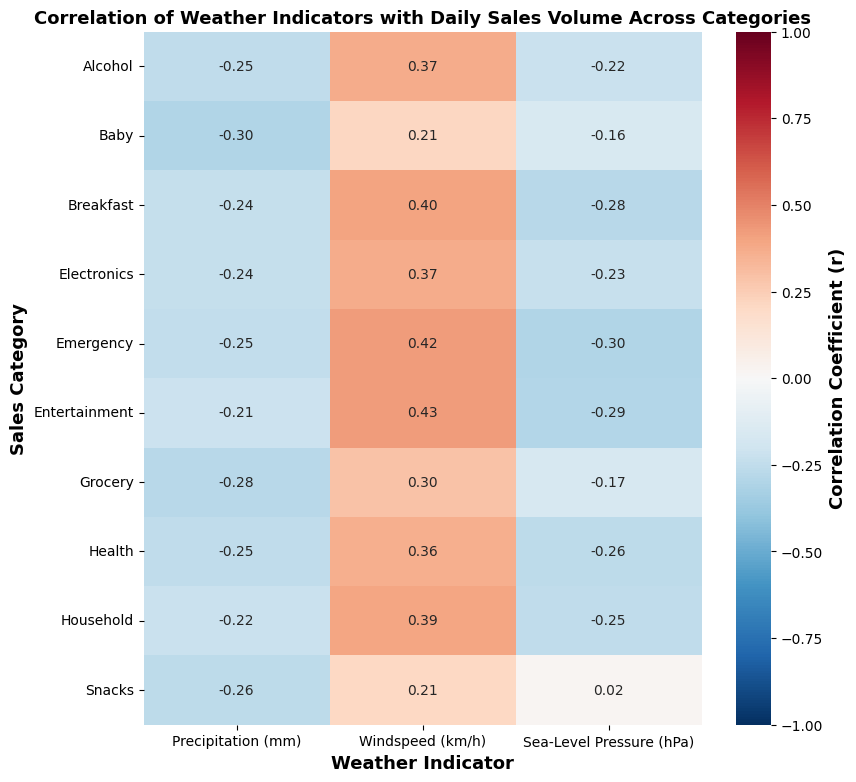

In [145]:
plt.figure(figsize = (9,9))
heatmap = sns.heatmap(correlation_frame, annot = True, fmt = '.2f', cmap = 'RdBu_r', vmin = -1, vmax = 1, xticklabels = ['Precipitation (mm)', 'Windspeed (km/h)', 'Sea-Level Pressure (hPa)'])
heat_bar = heatmap.collections[0].colorbar
heat_bar.set_label('Correlation Coefficient (r)', fontsize = 13, fontweight = 'bold')
plt.title('Correlation of Weather Indicators with Daily Sales Volume Across Categories', fontsize = 13, fontweight = 'bold')
plt.xlabel('Weather Indicator', fontsize = 13, fontweight = 'bold')
plt.ylabel('Sales Category', fontsize = 13, fontweight = 'bold')
plt.show()

The heatmap above reveals that all categories' sales volume share a positive correlation with windspeed (km/h). The windspeed weather indicator has correlation coefficients (r) all within the range 0.20 through 0.41. Among these categories, the emergency and entertainment categories have the highest correlation coefficients (r), equaling 0.41. Snacks has the lowest correlation coefficient (r), equaling 0.20. The precipitation (mm) weather indicator has correlation coefficients (r) all within the range -0.31 through -0.22 while the sea-level pressure (hPa) weather indicator has correlation coefficients (r) all within the range -0.29 through 0.02. Both precipitation and sea-level pressure have overwhelmingly negative correlation coefficients, indicating that there is a negative correlation between these weather indicators and sales volume across almost all categories. Only snacks in sea-level pressure has a positive correlation coefficient (r), equaling 0.02 (still very low). While the windspeed weather indicator did have positive correlation coefficients, they were not high enough to establish an extremely strong positive correlation. It can be concluded that among these weather indicators, windspeed is loosely positively correlated with daily sales volume across all categories while precipitation and sea-level pressure are loosely negatively correlated with daily sales volume across almost all categories. This suggests that windspeed is correlated with higher sales volume across categories while precipitation and sea-level pressure are correlated with lower sales volume across almost all categories, but this correlation alone isn't enough to establish causation.

#### Weather Severity Escalation and Purchasing Spikes Lag Table

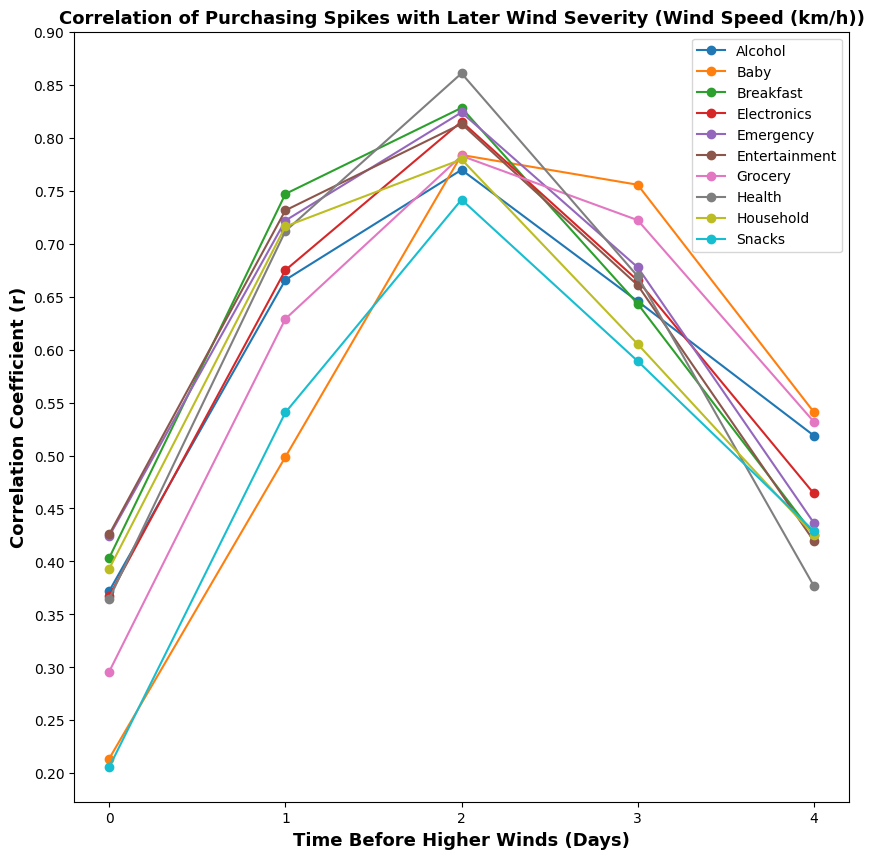

In [146]:
plt.figure(figsize = (10,10))
for sales_category in sales_categories:
    plt.plot(lag_range, lag_frame[sales_category], marker = 'o', label = sales_category)
plt.title('Correlation of Purchasing Spikes with Later Wind Severity (Wind Speed (km/h))', fontsize = 13, fontweight = 'bold')
plt.xlabel('Time Before Higher Winds (Days)', fontsize = 13, fontweight = 'bold')
plt.ylabel('Correlation Coefficient (r)', fontsize = 13, fontweight = 'bold')
plt.xticks(list(lag_range))
plt.yticks(np.arange(0.20, 0.95, 0.05))
plt.legend()
plt.show()

The line chart above reveals that the correlation between purchasing spikes and later weather severity (wind speed) peaks at two days before the anticipated higher winds. This is a consistent result across all categories, with every category experiencing their peak at 2 days before higher winds. This peak is preceded by a steep climb from day 0 and 1 and similarly followed by a steep decline for days 3 and 4. The baby and grocery categories experience the shallowest decline following day 2 while all categories share a similar incline rate prior to day 2. Health has the highest correlation coefficient (r), equaling around 0.87. Snacks has the lowest correlation coefficient (r), equaling around 0.74. Overall, there is a strong correlation between purchasing spikes and higher winds two days later. This indicates that there is a detectable lag of 2 days between weather severity escalation and purchasing spikes. This lag is likely the result of consumers purchasing an increased volume of goods across all categories in response to worsening weather as an anticipatory precaution, but correlation alone can't prove causation. I chose windspeed (km/h) as the weather indicator to detect a lag because it is associated with weather severity escalation, providing a good reflection of changing weather patterns.

# Reflection Questions

### Question 2: ETL Trade-offs

One decision we made regarding joining weather data was choosing to join weather data to sales data using a left join. We chose to use a left join in order to preserve all sales data as that is the supplied information that is necessary to retain. Given that weather data was joined on sales data by date, there will almost always be available weather information for that date, but omitting sales data leaves a void that can't be filled as easily. An alternative approach that could've been taken was using an inner join instead of a left join. This might have changed our results by causing entire rows where weather data couldn't be joined to sales data to be deleted, resulting in missing sales and weather entries. A left join still keeps the sales data for that row even if a match couldn't be found, but an inner join just deletes that row containing the unmatched sales data. We ultimately decided that using a left join was the safest and best approach, and this decision resulted in the preservation of all 24,648 rows and the successful joining of weather data to every sales data entry. In hindsight, given our results an inner join would've been just as safe, but our decision holds.